# Pools:
My sub-metric is the best **pool and spray park setup**. A neighborhood is best if it has more pools and spray parks and they are bigger. This notebook only uses the pools data set.

Here I am importing my data set

In [9]:
import pandas as pd

df = pd.read_csv("Poolsdata.csv")
df.head()

,_id,id,name,type,retired,water_source,capacity,image,neighborhood,council_district,ward,tract,public_works_division,pli_division,police_zone,fire_zone,latitude,longitude
0,1,899591542,Ammon,Pool,NaN,Pittsburgh Water and Sewer Authority,538000.0,https://tools.wprdc.org/images/pittsburgh/pool...,Bedford Dwellings,6,5,42003050900,3,5,2,2-5,40.448728,-79.978329
1,2,1003800828,Banksville,Pool,NaN,Pennsylvania American Water,166320.0,https://tools.wprdc.org/images/pittsburgh/pool...,Banksville,2,20,42003202300,5,20,6,4-9,40.414766,-80.040555
2,3,1688544652,Beechview Spray Park,Spray Park,NaN,Pennsylvania American Water,NaN,https://tools.wprdc.org/images/pittsburgh/pool...,Beechview,4,19,42003191600,5,19,6,4-28,40.414997,-80.019173
3,4,1533382756,Bloomfield,Pool,NaN,Pittsburgh Water and Sewer Authority,335000.0,https://tools.wprdc.org/images/pittsburgh/pool...,Bloomfield,7,8,42003080200,2,8,5,3-1,40.461997,-79.953313
4,5,1287441950,Burgwin Spray Park,Spray Park,NaN,Pittsburgh Water and Sewer Authority,NaN,https://tools.wprdc.org/images/pittsburgh/pool...,Hazelwood,5,15,42003562300,3,15,4,2-13,40.405073,-79.936899


In [10]:
pools.columns

Index(['_id', 'id', 'name', 'type', 'retired', 'water_source', 'capacity',
       'image', 'neighborhood', 'council_district', 'ward', 'tract',
       'public_works_division', 'pli_division', 'police_zone', 'fire_zone',
       'latitude', 'longitude'],
      dtype='object')

Here I get all of the data into columns for how they are described. Spray parks have no capacity listed so I count that as 0. Only 28 pools and spray parks exist so only the neighborhoods that have one show up below

In [11]:
pools["capacity"] = pools["capacity"].fillna(0)
pools[["name", "type", "capacity", "neighborhood"]]

,name,type,capacity,neighborhood
0,Ammon,Pool,538000.0,Bedford Dwellings
1,Banksville,Pool,166320.0,Banksville
2,Beechview Spray Park,Spray Park,0.0,Beechview
3,Bloomfield,Pool,335000.0,Bloomfield
4,Burgwin Spray Park,Spray Park,0.0,Hazelwood
5,Cowley Spray Park,Spray Park,0.0,Troy Hill
6,East Hills Spray Park,Spray Park,0.0,East Hills
7,Highland - Children,Pool,0.0,Highland Park
8,Highland - Main,Pool,560242.0,Highland Park
9,Homewood,Pool,171075.0,Homewood South


Now I have to group the data that I need which is the neighborhoods and then measure two things for each one. How many pools and spray parks it has and it's total capacity

In [12]:
tn = pools.groupby("neighborhood").agg(
    n_sites=("name", "size"),
    total_capacity=("capacity", "sum"),
)
tn.sort_values("n_sites", ascending=False).head()

,n_sites,total_capacity
neighborhood,,
South Side Flats,2,312800.0
Highland Park,2,560242.0
Bedford Dwellings,1,538000.0
Beechview,1,0.0
Beltzhoover,1,0.0


Those two numbers are on different scales, so I squish both to 0-1 and average them into one pool score

In [13]:
mm = lambda s: (s - s.min()) / (s.max() - s.min())

tn["pool_score"] = 0.5 * mm(tn["n_sites"]) + 0.5 * mm(tn["total_capacity"])
tn.sort_values("pool_score", ascending=False).head()

,n_sites,total_capacity,pool_score
neighborhood,,,
Highland Park,2,560242.0,1.000000
South Side Flats,2,312800.0,0.779165
Bedford Dwellings,1,538000.0,0.480150
Brookline,1,417657.0,0.372747
Mount Washington,1,356000.0,0.317720


Then I sort them all by value and scrape until I have the top 5 and the bottom 5. The bottom 5 are only neighborhoods that have a pool, they just have the smallest ones (spray parks)

In [14]:
# Sort values (highest score = best)
sorted_data = tn["pool_score"].sort_values()

print("Top 5 BEST:")
print(sorted_data.tail(5)[::-1])

print("\nTop 5 WORST:")
print(sorted_data.head(5))

Top 5 BEST:
neighborhood
Highland Park        1.000000
South Side Flats     0.779165
Bedford Dwellings    0.480150
Brookline            0.372747
Mount Washington     0.317720
Name: pool_score, dtype: float64

Top 5 WORST:
neighborhood
Beechview                   0.0
Beltzhoover                 0.0
Hazelwood                   0.0
East Hills                  0.0
Lincoln-Lemington-Belmar    0.0
Name: pool_score, dtype: float64


Here I graph every neighborhood's pool score so I can see the whole spread

<Axes: title={'center': 'Pool Score by Neighborhood'}, xlabel='Neighborhood', ylabel='Pool Score'>

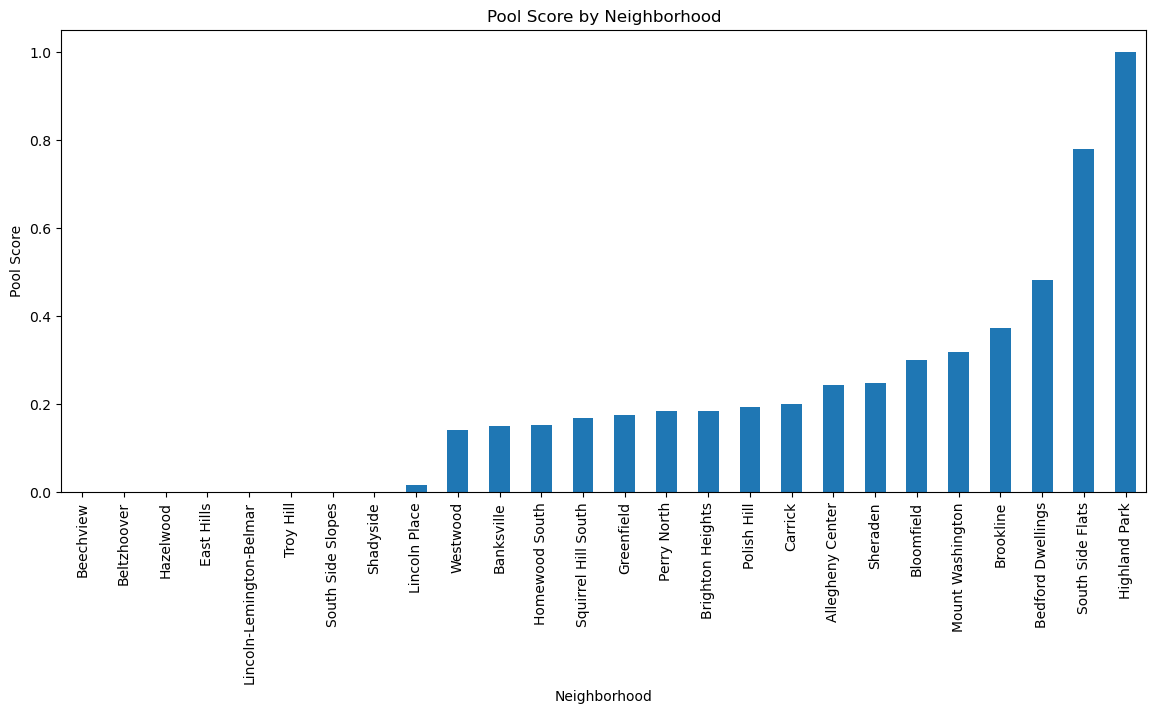

In [15]:
sorted_data.plot(
    kind='bar',
    title="Pool Score by Neighborhood",
    xlabel="Neighborhood",
    ylabel="Pool Score",
    figsize=(14,6),
    rot=90
)

Here I took the 10 best ones and graphed them on a bar graph

<Axes: title={'center': 'Top 10 Best Neighborhoods (Pool Score)'}, xlabel='Neighborhood', ylabel='Pool Score'>

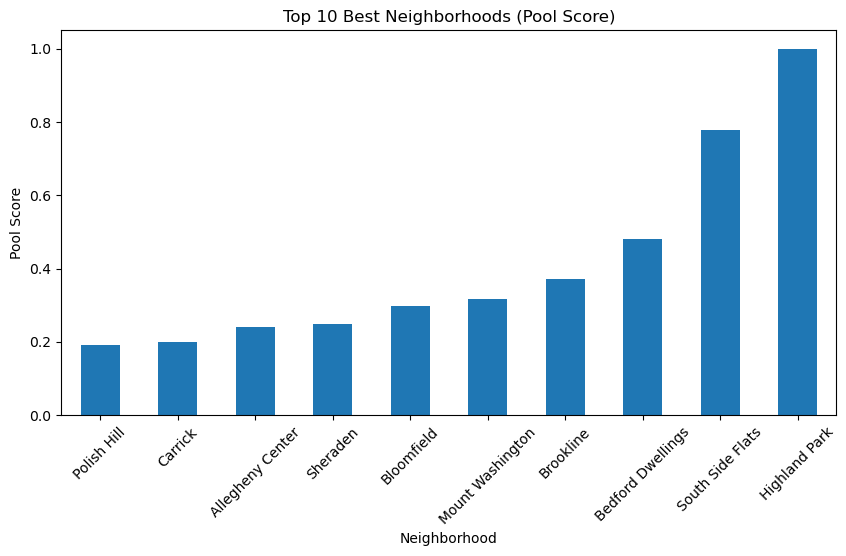

In [16]:
best10 = sorted_data.tail(10)

best10.plot(
    kind='bar',
    title="Top 10 Best Neighborhoods (Pool Score)",
    xlabel="Neighborhood",
    ylabel="Pool Score",
    figsize=(10,5),
    rot=45
)

Here I took the 10 worst ones and graphed them on a bar graph

<Axes: title={'center': 'Top 10 Worst Neighborhoods (Pool Score)'}, xlabel='Neighborhood', ylabel='Pool Score'>

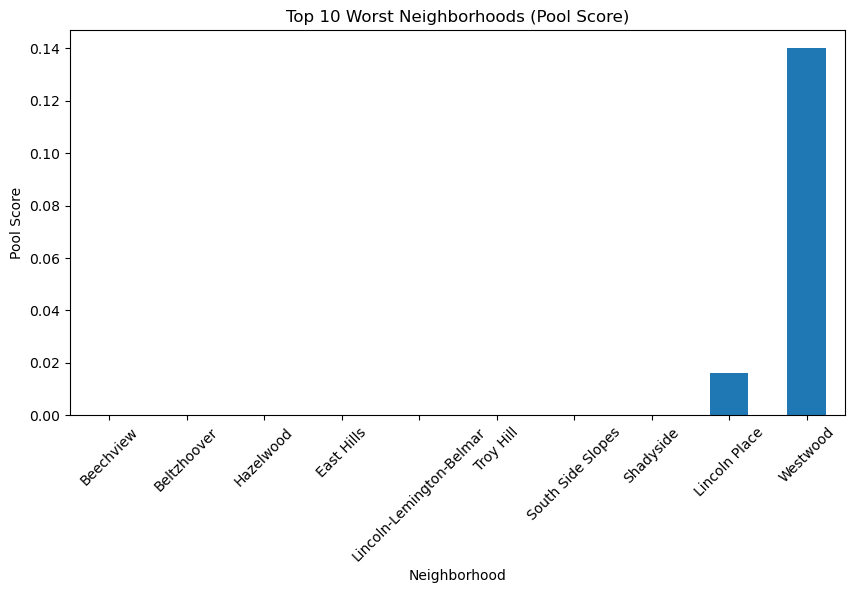

In [17]:
worst10 = sorted_data.head(10)

worst10.plot(
    kind='bar',
    title="Top 10 Worst Neighborhoods (Pool Score)",
    xlabel="Neighborhood",
    ylabel="Pool Score",
    figsize=(10,5),
    rot=45
)

## Result
**Highland Park** is the best by pools alone. It is the only neighborhood with a main pool and a children's pool, and it has the largest listed capacity. South Side Flats is second with two pools (Oliver and Ormsby), then Bedford Dwellings with one big pool.